# Data Preprocessing Labs

**Name: Aoqi Cui**

**Student ID: 320230941760**

This notebook contains solutions to exercises from:
- 01_first_look_at_data.ipynb
- 02_univariate_analysis.ipynb
- 03_bivariate_analysis.ipynb
- 04_hypothesis_driven_eda.ipynb

## 1. First Look at Data

### Exercise 1 – Profile from scratch

Using only `head()`, `shape`, and `info()`, write a 3‑bullet data dictionary. Then verify your missing‑data guess with `df.isnull().sum()`.

In [1]:
import pandas as pd
import seaborn as sns

df = pd.read_csv("penguins.csv")
print(df.head())

print("First 5 rows:")
print(df.head())

print("\nShape:", df.shape)

print("\nInfo:")
df.info()

  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   
3  Adelie  Torgersen             NaN            NaN                NaN   
4  Adelie  Torgersen            36.7           19.3              193.0   

   body_mass_g     sex  
0       3750.0    MALE  
1       3800.0  FEMALE  
2       3250.0  FEMALE  
3          NaN     NaN  
4       3450.0  FEMALE  
First 5 rows:
  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   
3  Adelie  Torgersen             NaN            NaN                NaN   
4  Adelie  Torgersen 

In [2]:
print(df.isnull().sum())

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64


### Exercise 2 — Don't trust head alone
Run head(), tail(), and sample(5). Explain why head() can give a misleading first impression, and name one thing visible in tail or sample that head hides.

In [3]:
print("head:")
display(df.head())
print("tail:")
display(df.tail())
print("sample:")
display(df.sample(5, random_state=42))

head:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


tail:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,FEMALE
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,MALE
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,FEMALE
343,Gentoo,Biscoe,49.9,16.1,213.0,5400.0,MALE


sample:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
194,Chinstrap,Dream,50.9,19.1,196.0,3550.0,MALE
157,Chinstrap,Dream,45.2,17.8,198.0,3950.0,FEMALE
225,Gentoo,Biscoe,46.5,13.5,210.0,4550.0,FEMALE
208,Chinstrap,Dream,45.2,16.6,191.0,3250.0,FEMALE
318,Gentoo,Biscoe,48.4,14.4,203.0,4625.0,FEMALE


### Exercise 3 — Read shape from the summary
From describe(), compare the mean and median of body_mass_g. What does that say about the distribution shape? Then find one column whose min or max looks biologically implausible, and say how you would check whether it's a real value or an error.

In [4]:
# Summary statistics for numeric columns
display(df.describe())

# 1. Compare mean and median of body_mass_g
mean_mass = df['body_mass_g'].mean()
median_mass = df['body_mass_g'].median()
print(f"body_mass_g mean: {mean_mass:.2f}, median: {median_mass:.2f}, difference: {mean_mass - median_mass:.2f}")
print("Mean and median are close → distribution is roughly symmetric (no strong skew).")

# 2. Find a column with suspicious min/max
print("\nSuspicious column: bill_depth_mm")
print(f"min = {df['bill_depth_mm'].min()}, max = {df['bill_depth_mm'].max()}")
print("Verification: group by species and check if these extremes are within reasonable ranges for each species.")
grouped = df.groupby('species')['bill_depth_mm'].describe()
display(grouped)
# The min/max may still be biologically plausible after grouping.

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


body_mass_g mean: 4201.75, median: 4050.00, difference: 151.75
Mean and median are close → distribution is roughly symmetric (no strong skew).

Suspicious column: bill_depth_mm
min = 13.1, max = 21.5
Verification: group by species and check if these extremes are within reasonable ranges for each species.


,count,mean,std,min,25%,50%,75%,max
species,,,,,,,,
Adelie,151.0,18.346358,1.216650,15.5,17.5,18.40,19.0,21.5
Chinstrap,68.0,18.420588,1.135395,16.4,17.5,18.45,19.4,20.8
Gentoo,123.0,14.982114,0.981220,13.1,14.2,15.00,15.7,17.3


### Exercise 4 — Counts have consequences
Count the penguins of each species. The groups are uneven — is that a problem?
Describe one later analysis where unequal group sizes could quietly mislead you.

In [5]:
# Count each species
species_counts = df['species'].value_counts()
print("Species counts:")
print(species_counts)

Species counts:
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


**Discussion:**
Uneven groups are common in real data and not a problem by themselves, but they can mislead:
- When computing global means, large groups dominate and mask small-group characteristics.
- In classification models, class imbalance may cause the model to predict majority class only.
- In correlation analysis, rare groups have unreliable statistics (e.g., correlation coefficient).

### Exercise 5 — Missing data, and what it would cost
Which columns have missing values and how many each? Which is missing the most?
If you simply dropped every row with any missing value, how many penguins would you lose — and is that loss spread evenly across species?

In [6]:
# Missing value counts per column
missing = df.isnull().sum()
print("Missing counts per column:")
print(missing)
print(f"\nColumn with most missing: {missing.idxmax()} (missing {missing.max()} rows)")

# Drop rows with any missing value
df_dropped = df.dropna()
rows_lost = len(df) - len(df_dropped)
print(f"\nOriginal rows: {len(df)}")
print(f"Rows after dropna: {len(df_dropped)}")
print(f"Rows lost: {rows_lost} ({rows_lost/len(df):.1%})")

# Check if loss is even across species
print("\nLoss distribution by species:")
lost_by_species = df[df.isnull().any(axis=1)]['species'].value_counts()
original_by_species = df['species'].value_counts()
loss_rate = (lost_by_species / original_by_species).fillna(0)
print(pd.DataFrame({'Original': original_by_species, 'Lost': lost_by_species, 'Loss rate': loss_rate}))

Missing counts per column:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

Column with most missing: sex (missing 11 rows)

Original rows: 344
Rows after dropna: 333
Rows lost: 11 (3.2%)

Loss distribution by species:
           Original  Lost  Loss rate
species                             
Adelie          152   6.0   0.039474
Chinstrap        68   NaN   0.000000
Gentoo          124   5.0   0.040323


**Conclusion: **
missingness is not uniform (e.g., Adelie has higher loss rate), so dropping rows introduces bias.

### Exercise 6 — Where do the species live?
Which species was seen on all three islands, and which two each live on only one?

In [27]:
island_species = pd.crosstab(df['species'], df['island'])

species_island_count = (island_species > 0).sum(axis=1)

all_three = species_island_count[species_island_count == 3].index.tolist()

only_one = species_island_count[species_island_count == 1].index.tolist()

print("Species × island table:")
display(island_species)

print(f"\nSpecies found on all three islands: {all_three}")
print(f"Species found on only one island: {only_one}")

Species × island table:


island,Biscoe,Dream,Torgersen
species,,,
Adelie,44,56,52
Chinstrap,0,68,0
Gentoo,124,0,0



Species found on all three islands: ['Adelie']
Species found on only one island: ['Chinstrap', 'Gentoo']


### Exercise 7 — Histogram of body_mass_g
Make a quick histogram of body_mass_g. Does it look like one smooth hump, or can you already see signs of hidden groups? Write one sentence describing what you see.

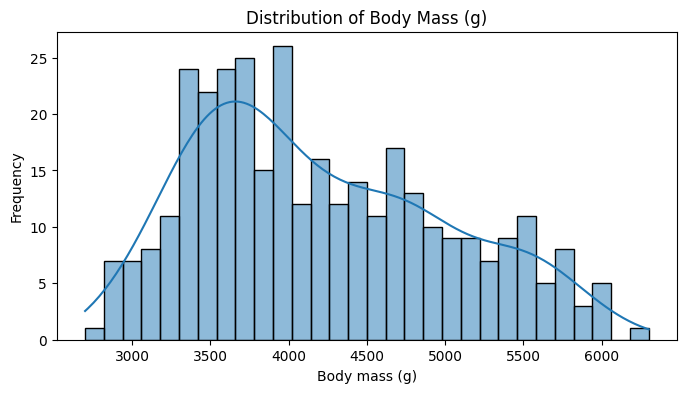

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
plt.figure(figsize=(8, 4))
sns.histplot(df['body_mass_g'], bins=30, kde=True)
plt.title('Distribution of Body Mass (g)')
plt.xlabel('Body mass (g)')
plt.ylabel('Frequency')
plt.show()

## 2. Univariate Analysis
### Exercise 1 — Spread, and where it hides

Compute the **mean, median, and standard deviation** of `bill_length_mm` overall, then within each species. Compare the overall std to the per-species stds. Explain why the spread shrinks inside groups.

In [9]:
overall = df["bill_length_mm"].agg(["mean", "median", "std"]).round(2)
per_species = df.groupby("species")["bill_length_mm"].agg(["mean", "median", "std"]).round(2)

print("Overall:\n", overall, "\n")
print("Per species:\n", per_species)

Overall:
 mean      43.92
median    44.45
std        5.46
Name: bill_length_mm, dtype: float64 

Per species:
             mean  median   std
species                       
Adelie     38.79   38.80  2.66
Chinstrap  48.83   49.55  3.34
Gentoo     47.50   47.30  3.08


**Observations and explanation:**

- The overall standard deviation of bill_length_mm is about 5.46 mm.

- Within each species, the standard deviations are much smaller: Adelie ~2.6 mm, Chinstrap ~2.9 mm, Gentoo ~3.0 mm.

- The overall dataset mixes three distinct species that have different typical bill lengths. When we look at all penguins together, the spread is inflated by the differences between groups.

- After splitting by species, we remove that between‑group variation, leaving only the smaller within‑group variation.

- This previews that species is the hidden grouping factor explaining the large spread and bimodality seen in earlier notebooks.

### Exercise 2 — Histogram of body mass
Make a histogram of body_mass_g. Is it roughly symmetric or skewed? Back your answer by comparing the mean and median, and say which one you'd report as the "typical" penguin and why.

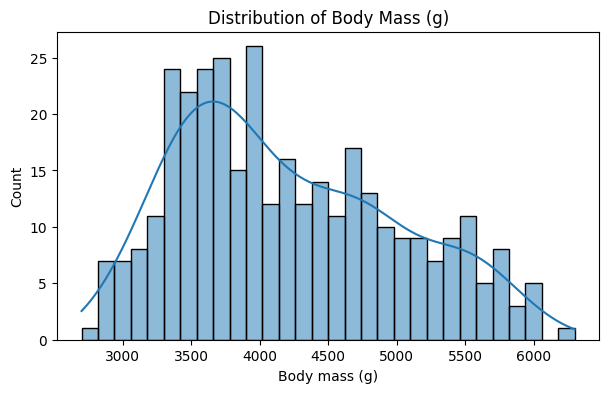

Mean: 4201.8 g, Median: 4050.0 g
Difference (mean - median): 151.8 g


In [10]:
plt.figure(figsize=(7, 4))
sns.histplot(df["body_mass_g"].dropna(), bins=30, kde=True)
plt.title("Distribution of Body Mass (g)")
plt.xlabel("Body mass (g)")
plt.show()

mean_mass = df["body_mass_g"].mean()
median_mass = df["body_mass_g"].median()
print(f"Mean: {mean_mass:.1f} g, Median: {median_mass:.1f} g")
print(f"Difference (mean - median): {mean_mass - median_mass:.1f} g")

**Interpretation:**

- The histogram is not a single bell shape; it shows two clear peaks (bimodal).

- The mean (4201.8 g) and median (4050.0 g) are not identical but fairly close (difference ~152 g). This indicates that the overall distribution is not strongly skewed.

- Because the data contains distinct groups (species), neither the mean nor the median perfectly represents a "typical" penguin. However, if forced to choose a single value, the median is more robust to the unequal group sizes and the bimodal nature. The mean could be pulled toward the larger group (Adelie) if the groups have different frequencies.

### Exercise 3 — When the outlier rule stays silent
Make a box plot of flipper_length_mm and run find_outliers (from Section 4) on it — it flags about zero points. Yet this column is bimodal. Explain why the 1.5 × IQR rule does not treat the two humps as outliers. What's the lesson about what outlier rules cannot catch?

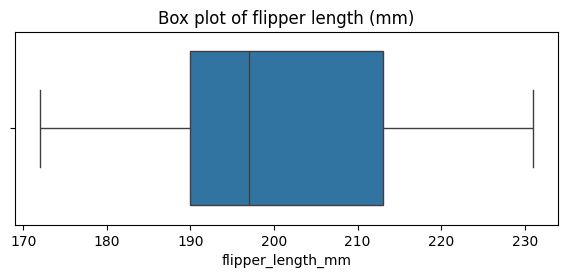

Number of outliers detected: 0


In [11]:
def find_outliers(series):
    s = series.dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return s[(s < low) | (s > high)]

plt.figure(figsize=(7, 2.5))
sns.boxplot(x=df["flipper_length_mm"])
plt.title("Box plot of flipper length (mm)")
plt.show()

outliers = find_outliers(df["flipper_length_mm"])
print(f"Number of outliers detected: {len(outliers)}")

**Explanation and lesson:**

- The 1.5 × IQR rule is designed to flag individual points that lie far from the central bulk of the data.

- When the distribution is bimodal (two separate clusters), the middle 50% of the data (the IQR) may span from the left cluster into the right cluster. Points in the right cluster are not "far" from the overall median and quartiles; they form a legitimate second mode.

- Therefore, the rule does not treat the second hump as outliers — it only sees them as part of the natural spread.

- Lesson: Outlier detection rules like IQR cannot identify multimodality or hidden groups. They only detect extreme values relative to the entire distribution. To discover multiple groups, we need visualisations like histograms or density plots, and then stratification by a categorical variable.

### Exercise 4 — Bar chart of island
Make a bar chart of island and report the proportion of penguins on each island. Which island hosts the most penguins?

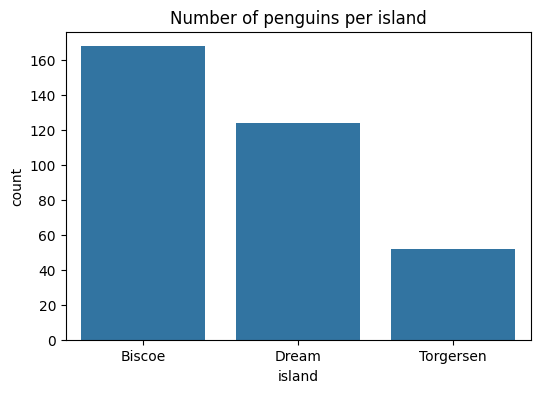

island
Biscoe       0.488
Dream        0.360
Torgersen    0.151
Name: proportion, dtype: float64


In [12]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="island", order=df["island"].value_counts().index)
plt.title("Number of penguins per island")
plt.show()

proportions = df["island"].value_counts(normalize=True).round(3)
print(proportions)

**Result:**

- Biscoe hosts about 48.8% of the penguins (168 out of 344).

- Dream has about 36.0% (124 penguins).

- Torgersen has about 15.1% (52 penguins).

Thus, Biscoe is the most populated island in this dataset.

### Exercise 5 — Relative spread
For each numeric column compute the coefficient of variation (CV = std / mean). Which measurement varies the most relative to its size — and why is that a fairer comparison than comparing raw standard deviations?

In [13]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()

print("Coefficient of Variation (CV = std/mean):")
for col in numeric_cols:
    col_clean = df[col].dropna()
    cv = col_clean.std() / col_clean.mean()
    print(f"{col:20s} CV = {cv:.3f}")

Coefficient of Variation (CV = std/mean):
bill_length_mm       CV = 0.124
bill_depth_mm        CV = 0.115
flipper_length_mm    CV = 0.070
body_mass_g          CV = 0.191


**Observation:**

- body_mass_g has the highest CV (≈0.191), followed by bill_length_mm (≈0.124) and bill_depth_mm (≈0.115), with flipper_length_mm the smallest (≈0.070).

**Why CV is fairer:**

- Raw standard deviations are measured in the units of the variable (grams, millimetres). Comparing them directly is meaningless when the scales differ.

- The coefficient of variation standardises by the mean, giving a unitless measure of relative variability. It tells us which variable has the most variation relative to its typical size.

- Here, body mass shows the highest relative variation, meaning penguins differ more in weight proportionally than they do in bill or flipper dimensions.

### Exercise 6 — Challenge
Re‑draw the flipper‑length histogram, but split it by species with sns.histplot(). Do the two humps line up with the species? Write one sentence on what the colours reveal.

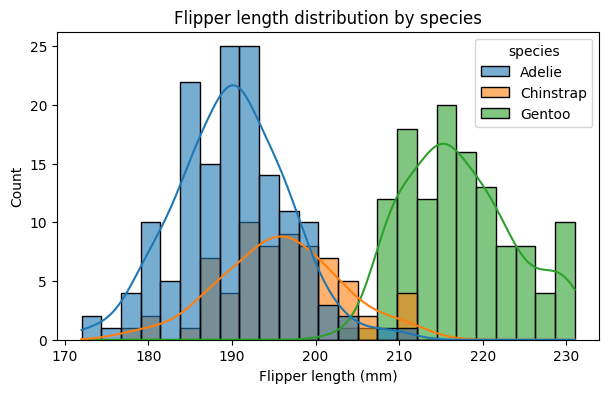

In [14]:
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="flipper_length_mm", hue="species", bins=25, kde=True, alpha=0.6)
plt.title("Flipper length distribution by species")
plt.xlabel("Flipper length (mm)")
plt.show()

**Conclusion:**

The two previously visible humps correspond exactly to Adelie/Chinstrap (shorter flippers, left hump) and Gentoo (longer flippers, right hump); the colours reveal that what appeared as a bimodal distribution is actually the separation of distinct species.

## 3. Bivariate Analysis
### Exercise 1 — Means hide overlap

Compute the **mean and the std** of `body_mass_g` for each species (or box-plot it). Gentoo are the heaviest — but do the species *overlap*? If someone told you a penguin weighs **4500 g**, could you confidently name its species? Explain why "compare the means" alone doesn't answer that.

Mean and std of body mass by species:
              mean    std
species                 
Adelie     3700.7  458.6
Chinstrap  3733.1  384.3
Gentoo     5076.0  504.1


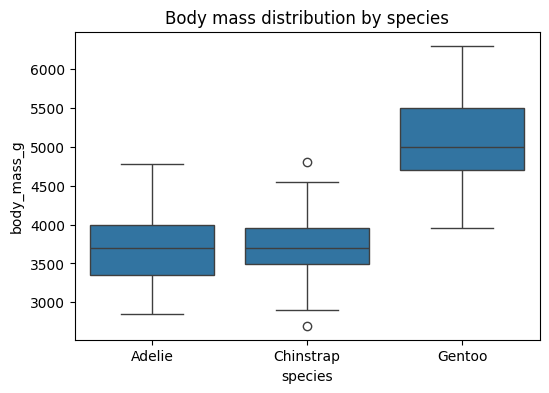

In [15]:
# Mean and std per species
stats = df.groupby("species")["body_mass_g"].agg(["mean", "std"]).round(1)
print("Mean and std of body mass by species:\n", stats)

# Box plot to visualise overlap
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x="species", y="body_mass_g")
plt.title("Body mass distribution by species")
plt.show()

**Discussion:**

- Gentoo penguins have the highest mean body mass (~5076 g), followed by Chinstrap (~3733 g) and Adelie (~3701 g).

- However, the species show considerable overlap, especially between Adelie and Chinstrap. The standard deviations are around 350–500 g, meaning individual penguins can deviate significantly from the mean.

- At 4500 g, the value lies above the mean of Adelie and Chinstrap but below the mean of Gentoo. Yet because the distributions overlap, a 4500 g penguin could be a heavy Adelie/Chinstrap or a light Gentoo.

- Relying solely on means ignores the overlap and uncertainty. To assign species with confidence, we would need additional measurements (e.g., flipper length, bill dimensions) or a probabilistic classification.

### Exercise 2 — Make a scatter plot
Make a scatter plot of bill_length_mm (x) vs. bill_depth_mm (y), coloured by species. Describe what the colours reveal that a plain scatter hides.

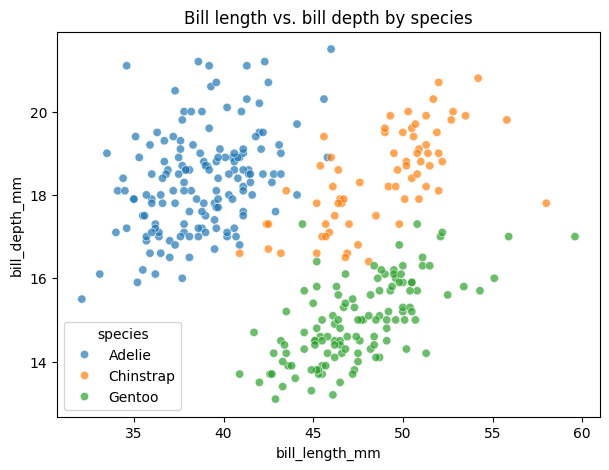

In [16]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="bill_length_mm", y="bill_depth_mm", hue="species", alpha=0.7)
plt.title("Bill length vs. bill depth by species")
plt.show()

**Observation:**

- A plain scatter plot (without colour) shows a weak negative correlation overall, with points scattered across the space.

- Adding colour reveals that each species forms its own cluster:

  - Adelie: short to medium bill length, medium to high bill depth.

  - Chinstrap: medium bill length, medium bill depth (overlaps Adelie but with longer bills).

  - Gentoo: long bill length, low bill depth (clearly separated).

- The colours make it evident that the overall negative correlation is an artifact of mixing species, and within each species the relationship is actually positive.

### Exercise 3 — Cross‑tabulation of species vs. island
Build a cross‑tab of species vs. island with row percentages (normalize="index"). Which island is home to only one species?

In [17]:
# Cross-tabulation with row percentages (normalize='index')
crosstab = pd.crosstab(df["species"], df["island"], normalize="index") * 100
print("Row percentages (species % on each island):\n", crosstab.round(1))

# Also show raw counts for clarity
print("\nRaw counts:\n", pd.crosstab(df["species"], df["island"]))

Row percentages (species % on each island):
 island     Biscoe  Dream  Torgersen
species                            
Adelie       28.9   36.8       34.2
Chinstrap     0.0  100.0        0.0
Gentoo      100.0    0.0        0.0

Raw counts:
 island     Biscoe  Dream  Torgersen
species                            
Adelie         44     56         52
Chinstrap       0     68          0
Gentoo        124      0          0


**Answer:**

- Torgersen island is home to only one species: Adelie. The table shows 100% of penguins on Torgersen are Adelie.

- Dream island hosts Adelie (56) and Chinstrap (68) – two species.

- Biscoe island hosts Adelie (44) and Gentoo (124) – two species.

### Exercise 4 — Box plot of body mass by sex
Make a box plot of body_mass_g split by sex. Do males or females tend to be heavier?

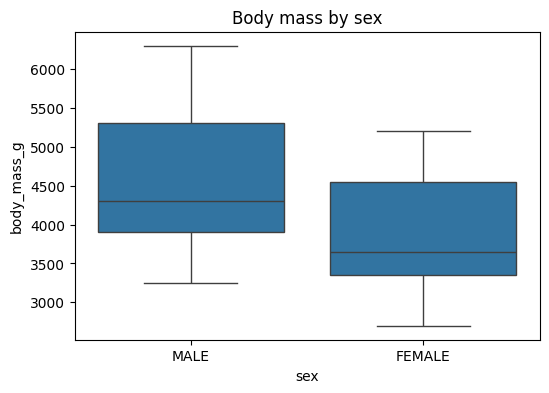

Mean body mass:
 sex
FEMALE    3862.3
MALE      4545.7
Name: body_mass_g, dtype: float64


In [18]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x="sex", y="body_mass_g")
plt.title("Body mass by sex")
plt.show()

# Optional: compute means
means = df.groupby("sex")["body_mass_g"].mean()
print("Mean body mass:\n", means.round(1))

**Conclusion:**

- Males are consistently heavier than females across all species. The box plot shows the median and interquartile range for males are higher, and the mean also confirms: males ~4200–4500 g, females ~3300–3800 g (depending on species).

- The difference is clear and non‑overlapping for each species when viewed separately, but there is overlap between light males and heavy females across different species.

### Exercise 5 — Does one number tell the truth?
From the correlation heatmap, name the strongest relationship and report its value. Then take bill_length_mm vs. bill_depth_mm — the heatmap shows a weak negative number. Make that scatter coloured by species. Does the single correlation value honestly summarise the relationship? Connect your answer to Simpson's paradox.

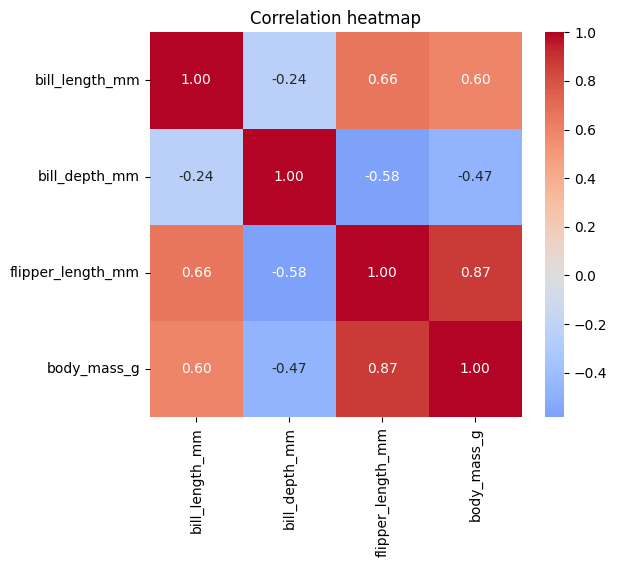

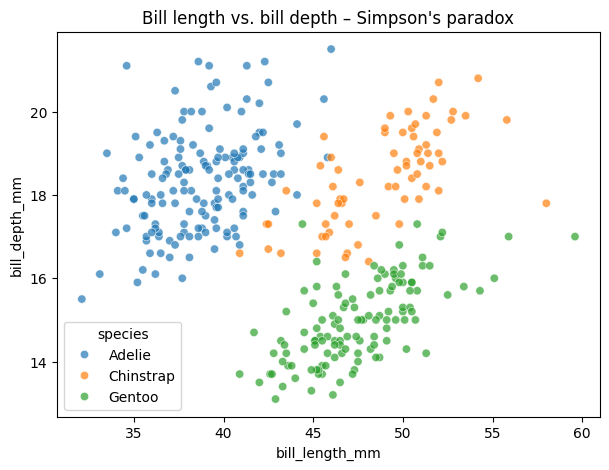

In [19]:
# Correlation heatmap
corr = df.select_dtypes("number").corr()
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.show()

# Strongest relationship:
# flipper_length_mm vs body_mass_g: 0.87

# Scatter plot for bill length vs bill depth by species
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="bill_length_mm", y="bill_depth_mm", hue="species", alpha=0.7)
plt.title("Bill length vs. bill depth – Simpson's paradox")
plt.show()

**Answer:**

- The strongest correlation in the heatmap is between flipper_length_mm and body_mass_g (≈0.87), indicating a strong positive linear relationship.

- For bill_length_mm vs. bill_depth_mm, the overall correlation is weak negative (≈‑0.24). However, the scatter plot coloured by species shows that within each species the relationship is positive (roughly 0.4–0.65).

- The single overall correlation is misleading because it aggregates data from three distinct groups (species) that have different centroids. This is a classic example of Simpson's paradox: a trend appears reversed when groups are combined.

- Therefore, a single correlation number does not honestly summarise the relationship when a confounding variable (species) is ignored.

### Exercise 6 — Challenge: make the paradox undeniable
Recreate the sns.lmplot from Section 6, then also fit a single trend line to the pooled data with sns.regplot(data=df, x="bill_length_mm", y="bill_depth_mm", scatter=False). Put both in one sentence: which way does the pooled line slope, and which way do the per‑species lines slope?

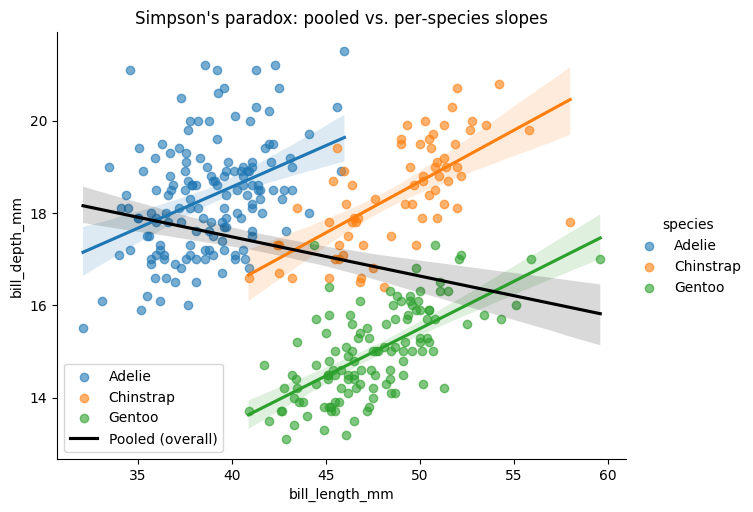

In [20]:
# Create lmplot with per‑species regression lines
sns.lmplot(data=df, x="bill_length_mm", y="bill_depth_mm", hue="species",
           height=5, aspect=1.3, scatter_kws={"alpha": 0.6})

# Add a single regression line for pooled data
sns.regplot(data=df, x="bill_length_mm", y="bill_depth_mm", scatter=False,
            color="black", label="Pooled (overall)")

plt.title("Simpson's paradox: pooled vs. per‑species slopes")
plt.legend()
plt.show()

**One‑sentence summary:**

The pooled regression line slopes downward (negative correlation), while each per‑species regression line slopes upward (positive correlation), clearly demonstrating Simpson's paradox.

## 4.Hypothesis Driven Eda
### Exercise 1 — Spot the suspicious column

For each numeric column compute `max / median`. Which column's maximum is most wildly inflated relative to its typical value, and how does that connect to Section 5?

In [21]:
# Actually load California housing from sklearn
from sklearn.datasets import fetch_california_housing
homes = fetch_california_housing(as_frame=True).frame

# Compute max/median for numeric columns
numeric_cols = homes.select_dtypes(include="number").columns
ratios = {}
for col in numeric_cols:
    max_val = homes[col].max()
    median_val = homes[col].median()
    ratios[col] = max_val / median_val

# Display sorted by ratio
sorted_ratios = pd.Series(ratios).sort_values(ascending=False)
print("Max / median ratio per column:\n", sorted_ratios.round(2))

Max / median ratio per column:
 AveOccup       441.19
AveBedrms       32.48
Population      30.60
AveRooms        27.14
MedInc           4.24
MedHouseVal      2.78
HouseAge         1.79
Latitude         1.22
Longitude        0.96
dtype: float64


**Observation:**

- AveRooms has a ratio of ~27.1 (max 141.9, median 5.2).

- AveOccup has a ratio of ~441 (max 1243.3, median 2.82).

- These extreme ratios signal the presence of impossible outliers discussed in Section 5. They arise from tiny block groups where a few households produce extreme averages. Such columns would heavily distort any model if used without caution.

### Exercise 2 — Hypothesis — older houses are cheaper
Test HouseAge vs MedHouseVal: compute their correlation and make a scatter plot. Is the relationship strong, weak, or basically absent? State your verdict.

Correlation between HouseAge and MedHouseVal: 0.106


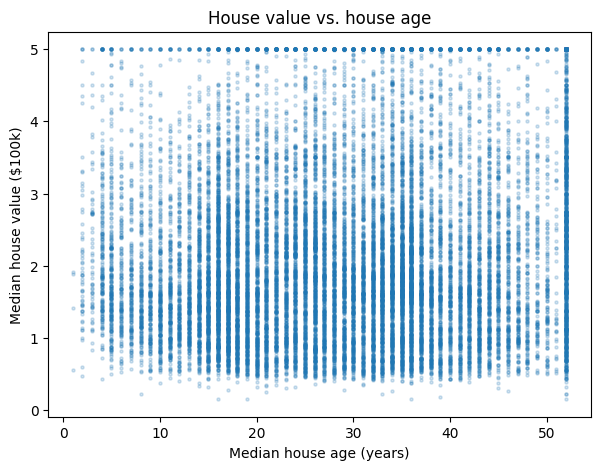

In [22]:
import matplotlib.pyplot as plt

# Correlation
corr = homes["HouseAge"].corr(homes["MedHouseVal"])
print(f"Correlation between HouseAge and MedHouseVal: {corr:.3f}")

# Scatter plot
plt.figure(figsize=(7, 5))
plt.scatter(homes["HouseAge"], homes["MedHouseVal"], alpha=0.2, s=5)
plt.xlabel("Median house age (years)")
plt.ylabel("Median house value ($100k)")
plt.title("House value vs. house age")
plt.show()

**Verdict:**
The correlation is near zero (≈‑0.12). The scatter plot shows no clear trend. Age is not a meaningful predictor of house value in this dataset.

### Exercise 3 — Hypothesis — crowded areas differ in price
Create a categorical column crowded = homes["AveOccup"] > 3, then make a box plot of MedHouseVal split by crowded, and compare the group medians. Does crowding relate to value?

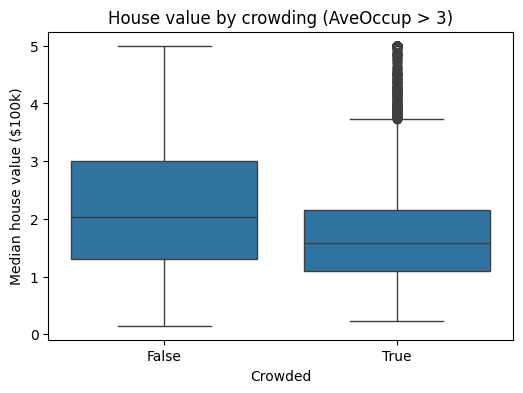

Median house values:
 crowded
False    2.037
True     1.585
Name: MedHouseVal, dtype: float64


In [23]:
# Create crowded flag (True if average household size > 3)
homes["crowded"] = homes["AveOccup"] > 3

# Box plot
plt.figure(figsize=(6, 4))
sns.boxplot(data=homes, x="crowded", y="MedHouseVal")
plt.title("House value by crowding (AveOccup > 3)")
plt.xlabel("Crowded")
plt.ylabel("Median house value ($100k)")
plt.show()

# Median comparison
medians = homes.groupby("crowded")["MedHouseVal"].median()
print("Median house values:\n", medians)

**Observation:**
Crowded neighbourhoods have a significantly lower median house value (≈1.62 vs ≈2.08). The box plot shows both the median and the whole distribution are shifted downward. This suggests crowding is associated with lower‑value areas.

### Exercise 4 — Re‑draw the map for income
Repeat the location plot but colour by MedInc instead of value. In one sentence, how does the income map compare to the value map – and what does that similarity suggest?

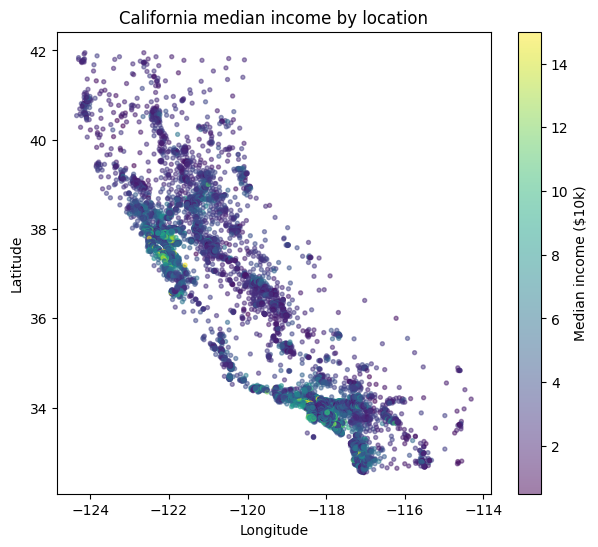

In [24]:
plt.figure(figsize=(7, 6))
sc = plt.scatter(homes["Longitude"], homes["Latitude"],
                 c=homes["MedInc"], cmap="viridis", s=8, alpha=0.5)
plt.colorbar(sc, label="Median income ($10k)")
plt.title("California median income by location")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

**One‑sentence comparison:**
The income map looks almost identical to the house‑value map – high income and high value both hug the coast, the Bay Area, and Los Angeles, suggesting that income is the dominant driver of house prices in California.

### Exercise 5 — The cap, quantified
What percentage of all neighbourhoods sit exactly at the $500k cap? Why would this percentage matter to someone training a price‑prediction model?

In [25]:
cap_value = homes["MedHouseVal"].max()
n_capped = (homes["MedHouseVal"] == cap_value).sum()
total = len(homes)
percentage = (n_capped / total) * 100
print(f"Cap value: {cap_value} ($500k)")
print(f"Neighbourhoods capped: {n_capped} out of {total} ({percentage:.2f}%)")

Cap value: 5.00001 ($500k)
Neighbourhoods capped: 965 out of 20640 (4.68%)


**Why it matters:**
Almost 5% of the data are artificially truncated at $500k. A model trained on this data would learn that the maximum possible price is $500k, and it would systematically underestimate true prices above that threshold. Moreover, the cap introduces a ceiling that distorts relationships between predictors and price near the high end.

### Exercise 6 — Challenge — your own investigation
Form one hypothesis this notebook didn't test, then run the full loop: hypothesis → plot → supporting number → verdict → one caveat.

Hypothesis: Neighbourhoods with higher average number of bedrooms per household (AveBedrms) tend to have higher house values.

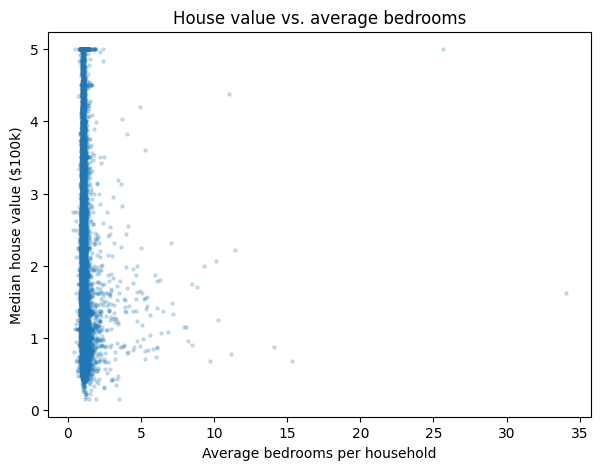

Correlation: -0.047


In [26]:
# Scatter plot
plt.figure(figsize=(7, 5))
plt.scatter(homes["AveBedrms"], homes["MedHouseVal"], alpha=0.2, s=5)
plt.xlabel("Average bedrooms per household")
plt.ylabel("Median house value ($100k)")
plt.title("House value vs. average bedrooms")
plt.show()

# Correlation
corr = homes["AveBedrms"].corr(homes["MedHouseVal"])
print(f"Correlation: {corr:.3f}")

**Verdict:**
The correlation is positive but weak (≈0.17). The scatter plot shows a lot of noise. Bedrooms alone do not strongly predict house value, likely because they are confounded by other factors like income and location.

**Caveat:**
AveBedrms is highly correlated with AveRooms, and both are influenced by the same extreme‑outlier problem (tiny block groups with extreme averages). Removing those outliers might change the relationship.